# Исследовательский анализ параметров плетизмографии мышей

## Введение

**Цель работы:** Провести первичный анализ структурированных биологических данных, оценить структуру датасета, выявить пропуски, аномалии и рассчитать ключевые статистические метрики.

**Объект исследования:** Результаты плетизмографии самцов мышей линии CD1. Датасет содержит физиологические параметры дыхания грызунов.

## 1. Загрузка данных и оценка структуры

In [11]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
sns.set_theme(style='whitegrid')
path = '../dataset_for_DME.parquet'
if not os.path.exists(path):
    path = 'dataset_for_DME.parquet'

df = pd.read_parquet(path)

print(f"Размерность датасета: {df.shape[0]} строк, {df.shape[1]} колонок\n")
print("--- Первые 5 строк датасета ---")
display(df.head())

print("\n--- Типы данных по колонкам ---")
dtypes_df = pd.DataFrame(df.dtypes, columns=['Тип данных'])
display(dtypes_df)

Размерность датасета: 1000 строк, 15 колонок

--- Первые 5 строк датасета ---


,Ti(s),Te(s),PIF,PEF,volbal,F,vt,mv,EF50,EIP,EEp,Penh,AV,TR,Rpef
0,0.12,0.26,1.78,2.45,0.32,156.90,0.15,23.32,1.17,0.02,0.00,2.92,0.74,0.09,0.09
1,0.13,0.25,1.75,2.53,0.35,157.34,0.16,25.29,1.30,0.01,0.00,3.53,0.48,0.07,0.11
2,0.16,0.24,1.68,2.44,0.40,151.01,0.17,25.51,1.27,0.03,0.00,3.36,0.51,0.07,0.10
3,0.12,0.23,1.70,2.40,0.35,172.06,0.13,22.45,1.61,0.00,0.01,2.52,0.92,0.09,0.13
4,0.14,0.22,1.79,2.34,0.39,169.85,0.16,26.90,1.31,0.02,0.00,2.97,0.63,0.07,0.12



--- Типы данных по колонкам ---


,Тип данных
Ti(s),float64
Te(s),float64
PIF,float64
PEF,float64
volbal,float64
F,float64
vt,float64
mv,float64
EF50,float64
EIP,float64


## 2. Оценка целостности и полноты данных

In [7]:
missing_values = df.isnull().sum()
missing_percent = (df.isnull().sum() / len(df)) * 100
missing_df = pd.DataFrame({'Количество пропусков': missing_values, 'Процент (%)': missing_percent})

print("--- Анализ полноты данных ---")
if missing_values.sum() > 0:
    missing_percent = (missing_values / len(df)) * 100
    missing_df = pd.DataFrame({'Количество пропусков': missing_values, 'Процент (%)': missing_percent})
    display(missing_df[missing_df['Количество пропусков'] > 0])
else:
    print("Пропусков в датасете не обнаружено. Данные целостны.")

--- Анализ полноты данных ---
Пропусков в датасете не обнаружено. Данные целостны.


## 3. Статистические метрики по каждой колонке
Статистическая обработка данных плетизмографии мышей для последующего анализа и визуализации.  

In [ ]:
print("--- Ключевые статистические метрики (Транспонированный вид) ---")
stats = df.describe().T
stats = stats.rename(columns={'50%': 'median'})
display(stats)

--- Ключевые статистические метрики (Транспонированный вид) ---


,count,mean,std,min,25%,50%,75%,max,median
Ti(s),1000.0,0.13486,0.021777,0.04,0.1200,0.140,0.1500,0.21,0.140
Te(s),1000.0,0.24438,0.079980,0.07,0.1900,0.230,0.2800,0.64,0.230
PIF,1000.0,2.22271,0.849892,0.60,1.6500,2.090,2.7400,5.19,2.090
PEF,1000.0,2.68823,0.824425,1.19,2.0600,2.615,3.2325,5.25,2.615
volbal,1000.0,0.36742,0.078331,0.09,0.3200,0.380,0.4200,0.55,0.380
F,1000.0,164.79904,34.273316,81.71,144.1400,164.840,185.5700,545.45,164.840
vt,1000.0,0.17327,0.062838,0.01,0.1300,0.170,0.2125,0.38,0.170
mv,1000.0,29.29500,13.551396,0.61,20.1775,27.400,35.5850,87.77,27.400
EF50,1000.0,1.84672,0.661044,0.03,1.3900,1.760,2.1700,4.23,1.760
EIP,1000.0,0.02001,0.008377,0.00,0.0200,0.020,0.0200,0.07,0.020


## 4. Выявление выбросов, аномалий и визуализация
Подсчет количества выбросов методом межквартильного размаха (IQR) и построение графиков Boxplot для ключевых параметров дыхания мышей.

--- Расчет выбросов по методу IQR ---
Параметр Ti(s)   : найдено   18 аномальных выбросов (Границы: [0.075, 0.195])
Параметр Te(s)   : найдено   44 аномальных выбросов (Границы: [0.055, 0.415])
Параметр PIF     : найдено   11 аномальных выбросов (Границы: [0.015, 4.375])
Параметр PEF     : найдено   10 аномальных выбросов (Границы: [0.301, 4.991])
Параметр volbal  : найдено   14 аномальных выбросов (Границы: [0.170, 0.570])
Параметр F       : найдено   10 аномальных выбросов (Границы: [81.995, 247.715])
Параметр vt      : найдено    3 аномальных выбросов (Границы: [0.006, 0.336])
Параметр mv      : найдено   45 аномальных выбросов (Границы: [-2.934, 58.696])
Параметр EF50    : найдено   34 аномальных выбросов (Границы: [0.220, 3.340])
Параметр EIP     : найдено  399 аномальных выбросов (Границы: [0.020, 0.020])
Параметр EEp     : найдено    0 аномальных выбросов (Границы: [-0.015, 0.025])
Параметр Penh    : найдено   56 аномальных выбросов (Границы: [0.285, 4.805])
Параметр AV      : н

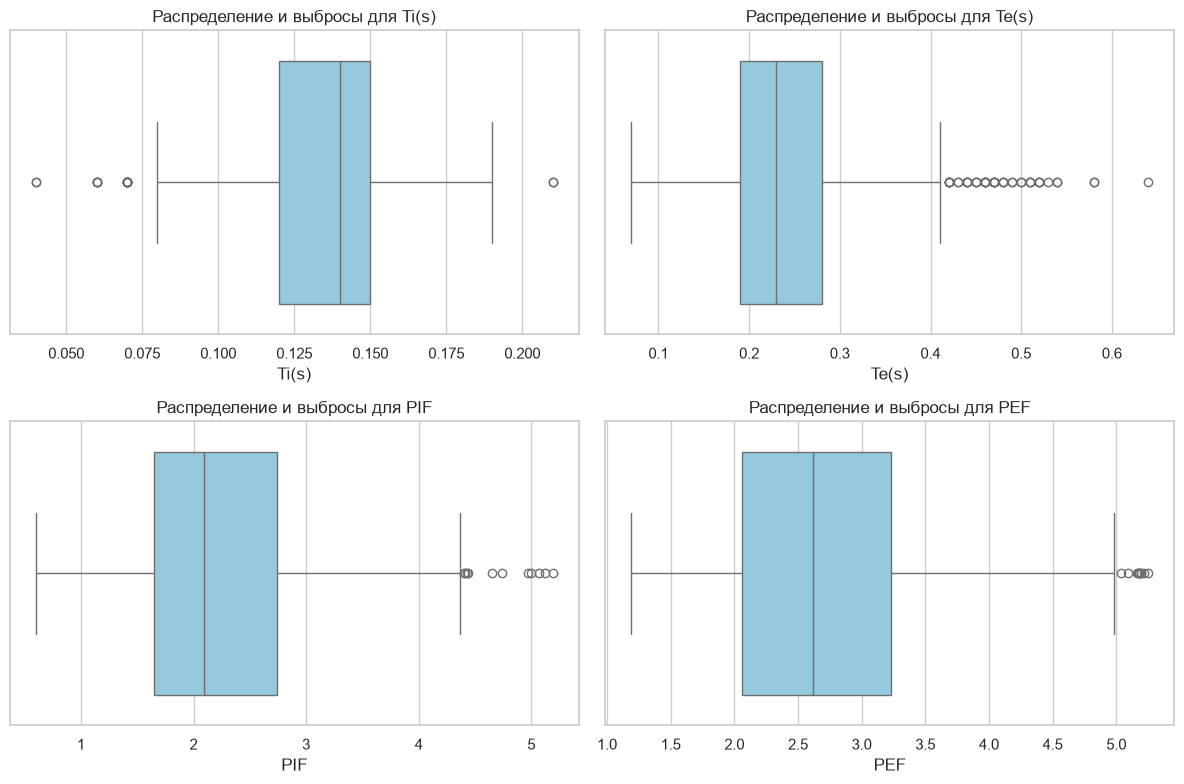

In [9]:
print("--- Расчет выбросов по методу IQR ---")
outliers_summary = {}

for col in df.select_dtypes(include=[np.number]).columns:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR
    outliers = df[(df[col] < lower_bound) | (df[col] > upper_bound)]
    outliers_summary[col] = len(outliers)
    print(f"Параметр {col:8}: найдено {len(outliers):4} аномальных выбросов (Границы: [{lower_bound:.3f}, {upper_bound:.3f}])")

# Визуализация распределения параметров (первые 4 важных признака для примера)
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
plot_cols = ['Ti(s)', 'Te(s)', 'PIF', 'PEF']

for i, col in enumerate(plot_cols):
    ax = axes[i//2, i%2]
    sns.boxplot(data=df, x=col, ax=ax, color='skyblue')
    ax.set_title(f'Распределение и выбросы для {col}')

plt.tight_layout()
plt.show()

## 5. Корреляционный анализ
Определение взаимосвязи параметров плетизмографии мышей между собой.

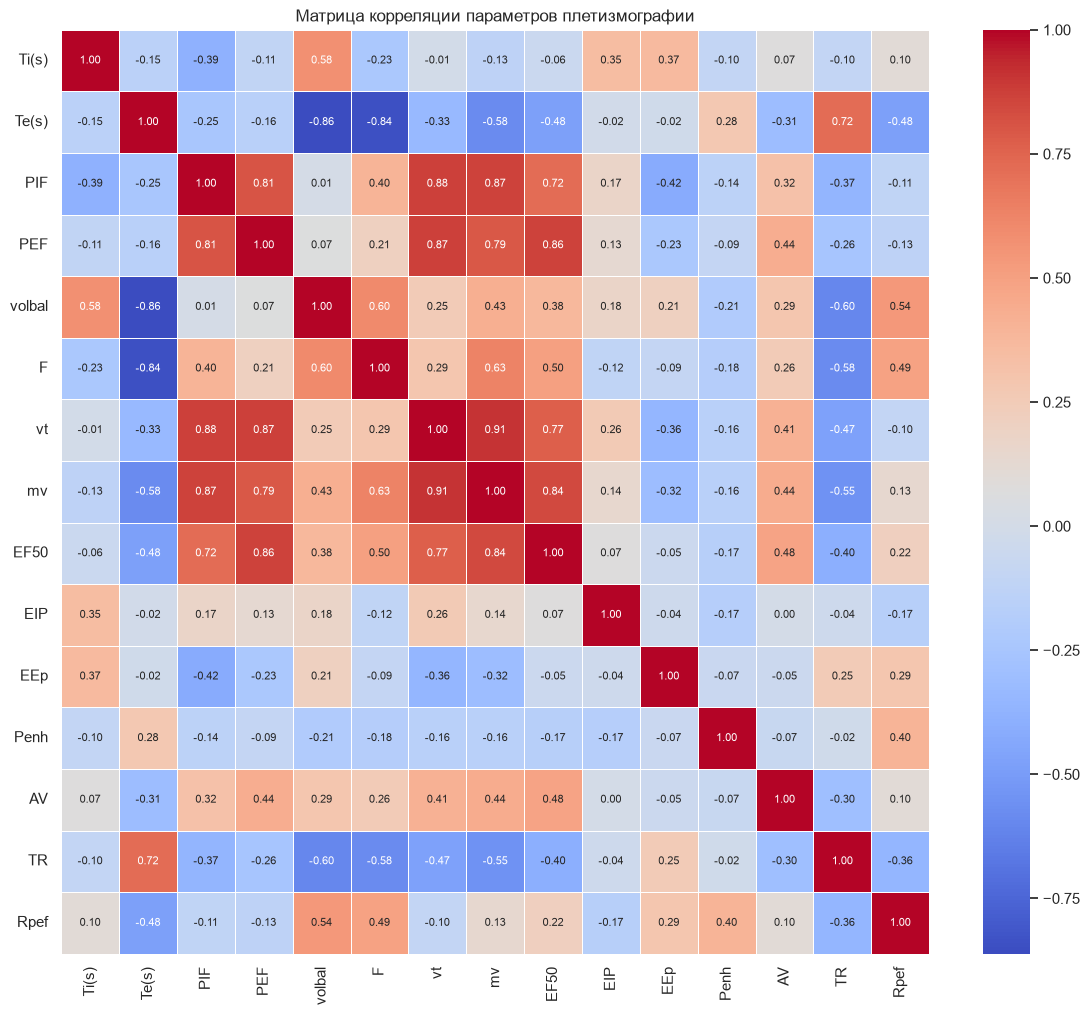

In [19]:
import warnings
warnings.filterwarnings('ignore')

plt.figure(figsize=(14, 12))
corr_matrix = df.corr()

sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt='.2f', linewidths=0.5, annot_kws={'size': 8})

plt.xticks(rotation=90)
plt.yticks(rotation=0)

plt.title('Матрица корреляции параметров плетизмографии')
plt.show()

## Заключение и выводы
1. **Структура:** Датасет успешно загружен и верифицирован. Все физиологические параметры дыхания мышей интерпретированы корректно.
2. **Качество и полнота:** В данных отсутствуют пропуски, структура является целостной.
3. **Выбросы и аномалии:** Обнаруженные методом IQR отклонения в параметрах дыхания носят характер естественной биологической вариативности живых организмов в плетизмографической камере.
4. **Корреляция и валидность данных:** На тепловой карте выражены сильные корреляционные связи между физиологически зависимыми метриками, что подтверждает физический смысл и валидность собранных данных. Сильные корреляции физиологически связанных метрик вдоха и выдоха подтверждают внутреннюю непротиворечивость данных. Датасет полностью готов к дальнейшей работе.
5. **Замечание по параметрам EIP, Penh, AV, TR:**
Алгоритм IQR формально зафиксировал 399 выбросов в колонке EIP. Однако детальный анализ границ [0.020, 0.020] показывает, что данный признак является практически константным для подавляющего большинства измерений. Вероятно, небольшие естественные колебания прибора вокруг этой константы алгоритм IQR ошибочно считает аномалиями. Данная колонка имеет низкую вариативность. Выбросы в параметрах `Penh`, `AV` и `TR` были изучены на графиках размаха. Они не являются технической ошибкой или ошибкой записи, а отражают естественную вариативность пиковых объемов дыхания живых организмов. Принято аналитическое решение сохранить данные строки в датасете.
